# Instalação do tensorflow, scikit-learn,matplotlib e seaborn

In [28]:
!pip install -q tensorflow scikit-learn matplotlib seaborn

# Import do dataset

**Antes de executar:** baixe o arquivo `EuroSAT_RGB.zip` pelo link indicado no repositório oficial do EuroSAT (https://github.com/phelber/EuroSAT) e faça o upload em `/content` pelo painel de arquivos do Colab.

A célula abaixo verifica se o arquivo está disponível e extrai as imagens em `/content/EuroSAT`.

In [29]:
import zipfile
import os

arquivo_zip = "/content/EuroSAT_RGB.zip"

if not os.path.exists(arquivo_zip):
    raise FileNotFoundError(
        "EuroSAT_RGB.zip não encontrado em /content. "
        "Baixe o arquivo pelo repositório oficial (https://github.com/phelber/EuroSAT) "
        "e faça o upload pelo painel de arquivos do Colab."
    )

print("Extraindo o dataset...")

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    zip_ref.extractall("/content/EuroSAT")

print("Dataset extraído com sucesso em /content/EuroSAT!")

# Confirma onde as pastas das classes foram extraídas
for root, dirs, files in os.walk("/content/EuroSAT"):
    if dirs:
        print(f"Caminho: {root} -> Pastas encontradas: {dirs[:10]}")
        break

Extraindo o dataset...
Dataset extraído com sucesso em /content/EuroSAT!
Conteúdo extraído:
Caminho: /content/EuroSAT -> Pastas encontradas: ['EuroSAT_RGB']


#Import das bibliotecas

In [30]:
import os
import json
import random
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("TensorFlow:", tf.__version__)
print("GPU disponível:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponível: []


In [31]:
caminho_zip = Path("/content/EuroSAT_RGB.zip")


for arquivo in Path("/content").iterdir():
    print(arquivo.name)


.config
EuroSAT_RGB.zip
EuroSAT
sample_data


In [32]:
caminho_base = Path("/content/EuroSAT")

#Indentificando as categorias

In [33]:
categorias = [
    "Residential",
    "Industrial",
    "Forest",
    "River"
]

caminhos_classes = {}

for categoria in categorias:

    encontrados = [
        pasta
        for pasta in caminho_base.rglob(categoria)
        if pasta.is_dir()
        and any(pasta.glob("*.jpg"))
    ]

    if not encontrados:

        raise FileNotFoundError(
            f"Pasta {categoria} não encontrada."
        )

    caminhos_classes[categoria] = encontrados[0]

    print(
        categoria,
        "->",
        caminhos_classes[categoria]
    )

Residential -> /content/EuroSAT/EuroSAT_RGB/Residential
Industrial -> /content/EuroSAT/EuroSAT_RGB/Industrial
Forest -> /content/EuroSAT/EuroSAT_RGB/Forest
River -> /content/EuroSAT/EuroSAT_RGB/River


# Selecionando 800 imagens

In [34]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

quantidade_por_classe = 200

imagens = []
rotulos = []

for categoria in categorias:

    arquivos = []

    for extensao in ["*.jpg", "*.jpeg", "*.png"]:

        arquivos.extend(
            caminhos_classes[categoria].glob(extensao)
        )

    arquivos = sorted(arquivos)

    if len(arquivos) < quantidade_por_classe:

        raise ValueError(
            f"A categoria {categoria} possui apenas "
            f"{len(arquivos)} imagens."
        )

    selecionadas = random.sample(
        arquivos,
        quantidade_por_classe
    )

    for arquivo in selecionadas:

        imagens.append(str(arquivo))
        rotulos.append(categoria)

print("Total de imagens:", len(imagens))

for categoria in categorias:

    print(
        categoria,
        ":",
        rotulos.count(categoria)
    )

Total de imagens: 800
Residential : 200
Industrial : 200
Forest : 200
River : 200


# Visualizando as imagens

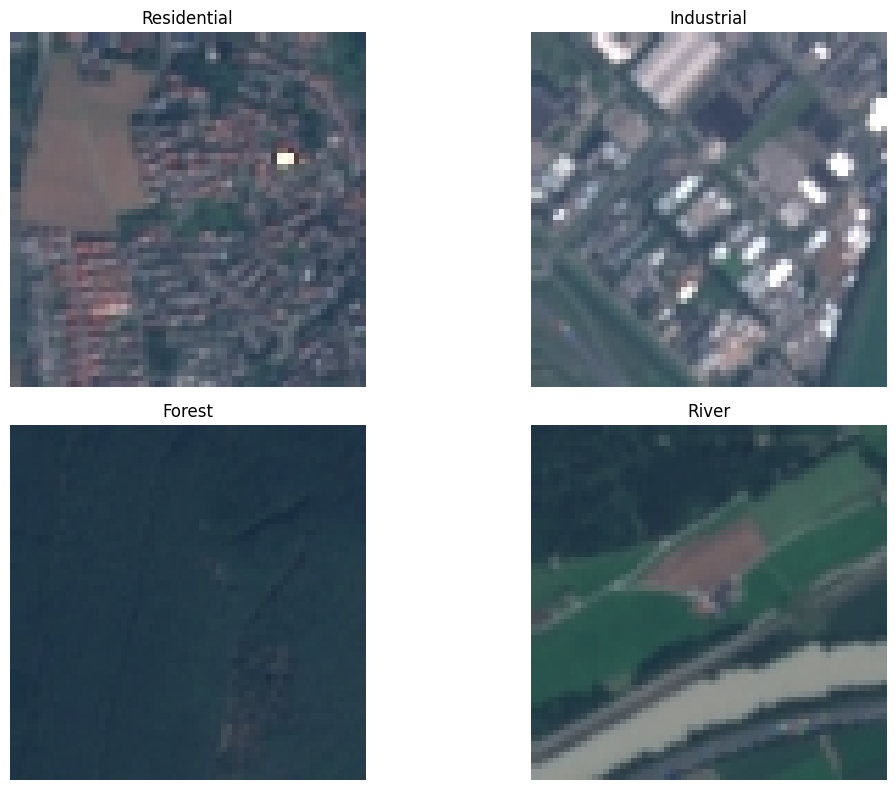

In [35]:
from PIL import Image
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i, categoria in enumerate(categorias):

    indice = rotulos.index(categoria)

    imagem = Image.open(imagens[indice])

    plt.subplot(2, 2, i + 1)

    plt.imshow(imagem)

    plt.title(categoria)

    plt.axis("off")

plt.tight_layout()
plt.show()

#Divisão dos dados

In [36]:
X = np.array(imagens)
y = np.array([
    categorias.index(rotulo)
    for rotulo in rotulos
])

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Treinamento:", len(X_train))
print("Validação:", len(X_val))
print("Teste:", len(X_test))

Treinamento: 560
Validação: 120
Teste: 120


# Redimensionamento e normalização

In [37]:
IMG_SIZE = 64

def carregar_imagens(caminhos, rotulos):

    imagens_processadas = []

    for caminho in caminhos:

        imagem = Image.open(caminho).convert("RGB")

        imagem = imagem.resize(
            (IMG_SIZE, IMG_SIZE)
        )

        imagem = np.array(
            imagem,
            dtype=np.float32
        )

        imagem = imagem / 255.0

        imagens_processadas.append(imagem)

    return (
        np.array(imagens_processadas),
        np.array(rotulos)
    )


X_train_img, y_train = carregar_imagens(
    X_train, y_train
)

X_val_img, y_val = carregar_imagens(
    X_val, y_val
)

X_test_img, y_test = carregar_imagens(
    X_test, y_test
)

print("Treinamento:", X_train_img.shape)
print("Validação:", X_val_img.shape)
print("Teste:", X_test_img.shape)

Treinamento: (560, 64, 64, 3)
Validação: (120, 64, 64, 3)
Teste: (120, 64, 64, 3)


# CNN 1: arquitetura básica

In [38]:
def criando_cnn_1():

    modelo = models.Sequential([

        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(
            32,
            (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64,
            (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dense(
            4,
            activation="softmax"
        )
    ])

    modelo.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

    return modelo


cnn_1 = criando_cnn_1()

cnn_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,117,188 (8.08 MB)

 Trainable params: 2,117,188 (8.08 MB)

 Non-trainable params: 0 (0.00 B)

# CNN 2: arquitetura intermediária

In [39]:
def criando_cnn_2():

    modelo = models.Sequential([

        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            128, (3, 3),
            activation="relu",
            padding="same"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dense(
            4,
            activation="softmax"
        )
    ])

    modelo.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

    return modelo


cnn_2 = criando_cnn_2()

cnn_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,188,644 (4.53 MB)

 Trainable params: 1,188,644 (4.53 MB)

 Non-trainable params: 0 (0.00 B)

# CNN 3: arquitetura com regularização

In [40]:
def criando_cnn_3():

    modelo = models.Sequential([

        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(
            32, (3, 3),
            padding="same"
        ),

        layers.BatchNormalization(),

        layers.Activation("relu"),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64, (3, 3),
            padding="same"
        ),

        layers.BatchNormalization(),

        layers.Activation("relu"),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            128, (3, 3),
            padding="same"
        ),

        layers.BatchNormalization(),

        layers.Activation("relu"),

        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dropout(0.4),

        layers.Dense(
            4,
            activation="softmax"
        )
    ])

    modelo.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

    return modelo


cnn_3 = criando_cnn_3()

cnn_3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,172 (434.27 KB)

 Trainable params: 110,724 (432.52 KB)

 Non-trainable params: 448 (1.75 KB)

# Treinamento das arquiteturas

## Função de treinamento

In [41]:
def treinar_modelo(modelo, nome):

    caminho_modelo = f"/content/{nome}_melhor.keras"

    callbacks = [

        EarlyStopping(
            monitor="val_accuracy",
            mode="max",
            patience=6,
            restore_best_weights=True
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=0.00001
        ),

        ModelCheckpoint(
            filepath=caminho_modelo,
            monitor="val_accuracy",
            mode="max",
            save_best_only=True
        )
    ]

    historico = modelo.fit(

        X_train_img,
        y_train,

        validation_data=(
            X_val_img,
            y_val
        ),

        epochs=30,

        batch_size=32,

        callbacks=callbacks,

        verbose=1
    )

    melhor_modelo = tf.keras.models.load_model(
        caminho_modelo
    )

    return melhor_modelo, historico

In [42]:
modelos_iniciais = {

    "CNN 1": cnn_1,

    "CNN 2": cnn_2,

    "CNN 3": cnn_3
}

modelos_treinados = {}

historicos = {}

for nome, modelo in modelos_iniciais.items():

    print("\n" + "=" * 50)

    print("INICIANDO:", nome)

    print("=" * 50)

    melhor_modelo, historico = treinar_modelo(
        modelo,
        nome.replace(" ", "_").lower()
    )

    modelos_treinados[nome] = melhor_modelo

    historicos[nome] = historico


INICIANDO: CNN 1
Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 14s 426ms/step - accuracy: 0.4054 - loss: 1.1904 - val_accuracy: 0.5500 - val_loss: 0.8833 - learning_rate: 0.0010
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 451ms/step - accuracy: 0.6179 - loss: 0.8272 - val_accuracy: 0.6167 - val_loss: 0.7414 - learning_rate: 0.0010
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 252ms/step - accuracy: 0.7018 - loss: 0.6597 - val_accuracy: 0.6500 - val_loss: 0.6308 - learning_rate: 0.0010
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 266ms/step - accuracy: 0.7304 - loss: 0.5994 - val_accuracy: 0.6917 - val_loss: 0.6614 - learning_rate: 0.0010
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 189ms/step - accuracy: 0.7982 - loss: 0.5220 - val_accuracy: 0.7083 - val_loss: 0.5920 - learning_rate: 0.0010
Epoch 6/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 190ms/step - accuracy: 0.8161 - loss: 0.4740 - val_accuracy: 0.7583 - val_loss: 0.5431 - learning_rate: 0.0010
Epoch 7/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 252ms/step - accuracy: 0.833

## CNN 3b: teste de ajuste do BatchNormalization

A CNN 3 apresentou forte divergência entre treinamento e validação: a acurácia de treinamento aumentou, enquanto a validação caiu e permaneceu próxima de 25%, com crescimento da loss de validação. O melhor resultado registrado foi na primeira época, e o EarlyStopping encerrou o treinamento na época 7.

Esse comportamento é compatível com dificuldade de generalização e pode estar relacionado ao comportamento das médias móveis do BatchNormalization. Entretanto, essa relação ainda é uma hipótese: com apenas 18 passos por época, as estimativas usadas na inferência podem não estar suficientemente estabilizadas.

Para investigar essa hipótese, a CNN 3b mantém a arquitetura e os parâmetros de treinamento da CNN 3, alterando somente `momentum` do BatchNormalization para `0.9`. Assim, a comparação ajuda a avaliar se essa alteração melhora o desempenho de validação.


In [43]:
def criando_cnn_3b():
    modelo = models.Sequential([
        layers.Input(shape=(64, 64, 3)),
        layers.Conv2D(32, (3, 3), padding="same"),
        layers.BatchNormalization(momentum=0.9),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding="same"),
        layers.BatchNormalization(momentum=0.9),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), padding="same"),
        layers.BatchNormalization(momentum=0.9),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(4, activation="softmax"),
    ])

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo


# Treinamento da CNN 3b com a mesma função e os mesmos parâmetros
# utilizados nas demais arquiteturas.
melhor_3b, hist_3b = treinar_modelo(criando_cnn_3b(), "cnn_3b")

modelos_treinados["CNN 3b"] = melhor_3b
historicos["CNN 3b"] = hist_3b

print("Melhor val_accuracy CNN 3b:", max(hist_3b.history["val_accuracy"]))
print("Melhor val_loss CNN 3b:", min(hist_3b.history["val_loss"]))


Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 415ms/step - accuracy: 0.6554 - loss: 0.8484 - val_accuracy: 0.2500 - val_loss: 2.1223 - learning_rate: 0.0010
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 322ms/step - accuracy: 0.7964 - loss: 0.5124 - val_accuracy: 0.3667 - val_loss: 1.4894 - learning_rate: 0.0010
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 325ms/step - accuracy: 0.8536 - loss: 0.3938 - val_accuracy: 0.7667 - val_loss: 0.5900 - learning_rate: 0.0010
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 377ms/step - accuracy: 0.8804 - loss: 0.3138 - val_accuracy: 0.7250 - val_loss: 0.7326 - learning_rate: 0.0010
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 321ms/step - accuracy: 0.8679 - loss: 0.3211 - val_accuracy: 0.8250 - val_loss: 0.4619 - learning_rate: 0.0010
Epoch 6/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 396ms/step - accuracy: 0.9036 - loss: 0.2523 - val_accuracy: 0.7917 - val_loss: 0.5353 - learning_rate: 0.0010
Epoch 7/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 377ms/step - accuracy: 0.9268 - loss: 0.2258

### Interpretação do experimento CNN 3b

A CNN 3b atingiu **92,50%** de acurácia de validação, superando a CNN 2 (89,17%), e foi selecionada como melhor arquitetura. Em relação à CNN 3 (35,83%), a única alteração foi o `momentum` do BatchNormalization, de 0,99 (padrão) para 0,9.

A validação da CNN 3b ainda oscilou nas primeiras épocas (por exemplo, 66,67% de acurácia com val_loss de 2,29 na época 9) e só estabilizou depois que o `ReduceLROnPlateau` reduziu a taxa de aprendizado. Por isso, o resultado favorece o ajuste do `momentum` neste experimento, mas não prova isoladamente que ele foi a única causa da melhora.

A tabela, os gráficos, a avaliação no conjunto de teste e o arquivo `configuracao.json` abaixo já consideram a CNN 3b, pois ela foi adicionada aos dicionários de modelos e históricos antes da etapa de comparação.

# Análise e Comparação dos resultados

A comparação inclui CNN 1, CNN 2, CNN 3 e CNN 3b.


## Gráficos de Acurácia e Loss

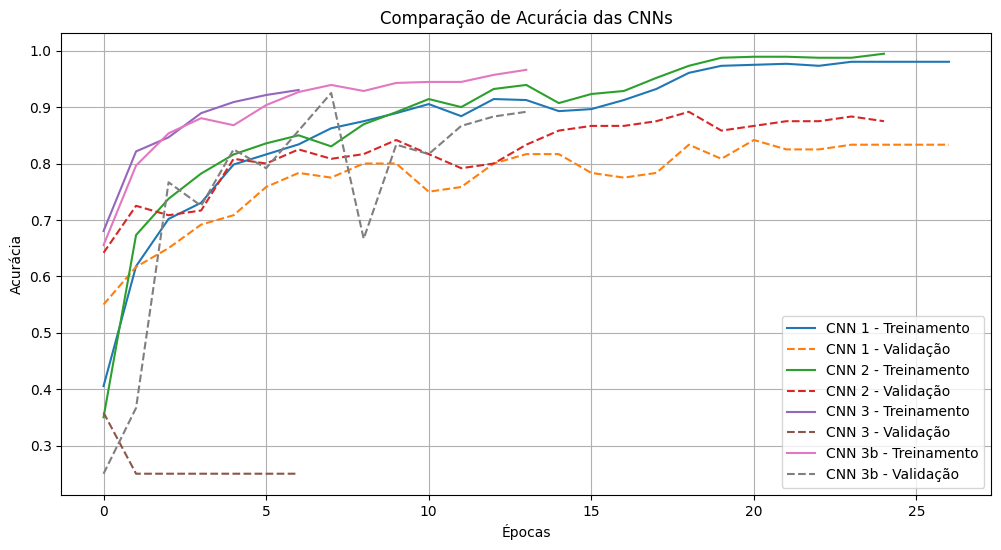

In [44]:
plt.figure(figsize=(12, 6))

for nome, historico in historicos.items():

    plt.plot(
        historico.history["accuracy"],
        label=f"{nome} - Treinamento"
    )

    plt.plot(
        historico.history["val_accuracy"],
        linestyle="--",
        label=f"{nome} - Validação"
    )

plt.title("Comparação de Acurácia das CNNs")

plt.xlabel("Épocas")

plt.ylabel("Acurácia")

plt.legend()

plt.grid()

plt.show()

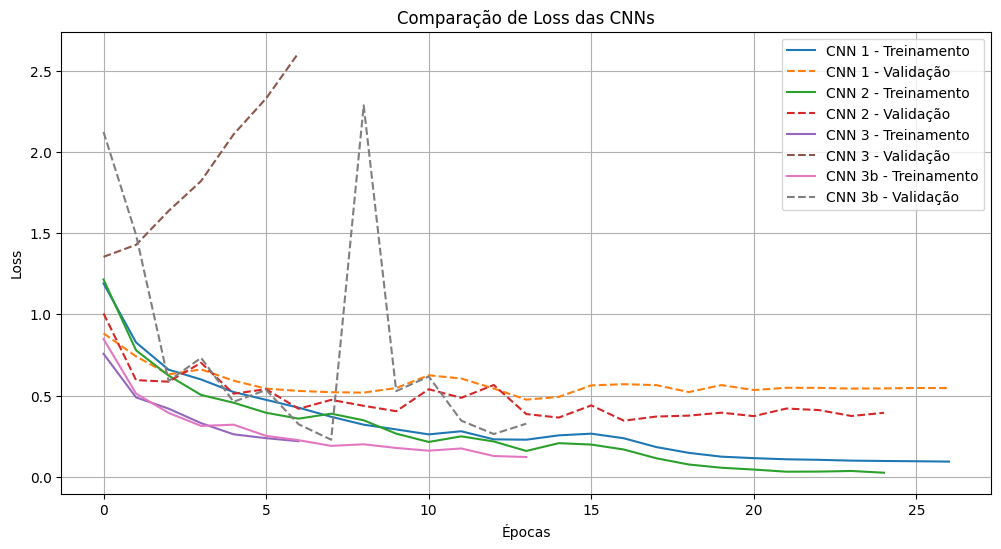

In [45]:
plt.figure(figsize=(12, 6))

for nome, historico in historicos.items():

    plt.plot(
        historico.history["loss"],
        label=f"{nome} - Treinamento"
    )

    plt.plot(
        historico.history["val_loss"],
        linestyle="--",
        label=f"{nome} - Validação"
    )

plt.title("Comparação de Loss das CNNs")

plt.xlabel("Épocas")

plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()

# Avaliando o Melhor Modelo

## Avaliação no conjunto de testes

In [46]:
import pandas as pd

# Criando o DataFrame de resultados a partir dos históricos de treino
resultados_lista = []
for nome, hist in historicos.items():
    melhor_val_acc = max(hist.history["val_accuracy"])
    resultados_lista.append({"Modelo": nome, "Melhor Val Accuracy": melhor_val_acc})

df_resultados = pd.DataFrame(resultados_lista).sort_values(by="Melhor Val Accuracy", ascending=False)

print("Tabela de Resultados na Validação:")
print(df_resultados)

# Selecionando o melhor modelo conforme os resultados
melhor_nome = df_resultados.iloc[0]["Modelo"]
melhor_modelo = modelos_treinados[melhor_nome]

print("\nMelhor arquitetura:", melhor_nome)

perda_teste, acuracia_teste = melhor_modelo.evaluate(
    X_test_img,
    y_test,
    verbose=0
)

print("\nResultados no conjunto de teste:")
print("Loss:", round(perda_teste, 4))
print("Accuracy:", round(acuracia_teste, 4))

Tabela de Resultados na Validação:
   Modelo  Melhor Val Accuracy
3  CNN 3b             0.925000
1   CNN 2             0.891667
0   CNN 1             0.841667
2   CNN 3             0.358333

Melhor arquitetura: CNN 3b

Resultados no conjunto de teste:
Loss: 0.1593
Accuracy: 0.9417


## Precision, Recall e F1-score

In [47]:
y_prob = melhor_modelo.predict(X_test_img)

y_pred = np.argmax(y_prob, axis=1)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=categorias,
        digits=4
    )
)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step
              precision    recall  f1-score   support

 Residential     0.9677    1.0000    0.9836        30
  Industrial     1.0000    0.9667    0.9831        30
      Forest     0.9615    0.8333    0.8929        30
       River     0.8529    0.9667    0.9062        30

    accuracy                         0.9417       120
   macro avg     0.9456    0.9417    0.9414       120
weighted avg     0.9456    0.9417    0.9414       120



## Matriz de confusão

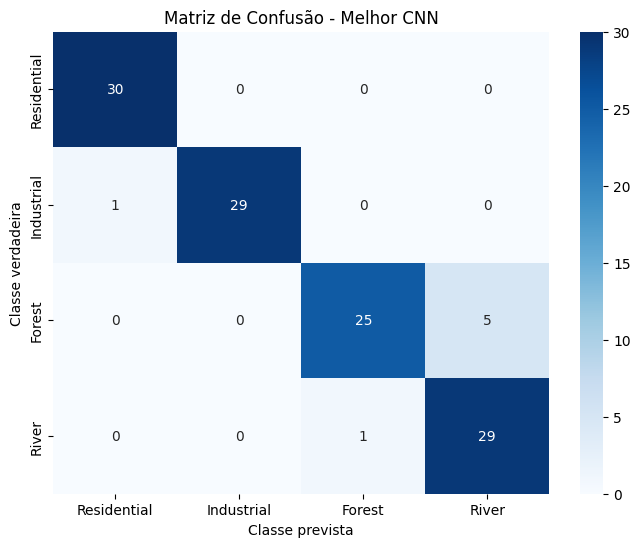

In [48]:
matriz = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=categorias,
    yticklabels=categorias
)

plt.title("Matriz de Confusão - Melhor CNN")

plt.xlabel("Classe prevista")

plt.ylabel("Classe verdadeira")

plt.show()

# Exportando o melhor modelo para o site

## Salvando a melhor CNN

In [49]:
melhor_modelo.save(
    "/content/melhor_modelo.keras"
)

configuracao = {

    "categorias": categorias,

    "tamanho_imagem": 64,

    "ordem_classes": {
        categoria: indice
        for indice, categoria in enumerate(categorias)
    },

    "melhor_arquitetura": melhor_nome
}

with open(
    "/content/configuracao.json",
    "w"
) as arquivo:

    json.dump(
        configuracao,
        arquivo,
        indent=4
    )

print("Modelo exportado com sucesso!")

print("Arquitetura selecionada:", melhor_nome)

Modelo exportado com sucesso!
Arquitetura selecionada: CNN 3b


## Baixando

In [50]:
from google.colab import files

files.download(
    "/content/melhor_modelo.keras"
)

files.download(
    "/content/configuracao.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Aplicação web (Gradio)

A célula abaixo disponibiliza a melhor CNN em uma interface web acessível pelo navegador. Com `share=True`, o Gradio gera um endereço público temporário; para obter um novo endereço, basta executar novamente o notebook até esta célula.

O usuário envia uma imagem de satélite, que é convertida para RGB, redimensionada para 64 × 64 e normalizada (÷ 255), da mesma forma que no treinamento. A interface exibe a imagem enviada, a categoria prevista e a probabilidade de cada uma das quatro classes.

Também foi desenvolvida uma versão local com Flask, HTML, CSS e JavaScript (pasta `GS-Classificacao_de_imagens-main`), que usa os arquivos `melhor_modelo.keras` e `configuracao.json` exportados acima.

In [51]:
# Aplicação web com Gradio (executável direto pelo notebook)
!pip install -q gradio

import gradio as gr
from PIL import Image
import numpy as np

def classificar_imagem(imagem):
    if imagem is None:
        return {}
    img = Image.fromarray(imagem).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    arr = np.array(img, dtype=np.float32) / 255.0
    arr = np.expand_dims(arr, axis=0)
    probs = melhor_modelo.predict(arr, verbose=0)[0]
    return {categoria: float(probs[i]) for i, categoria in enumerate(categorias)}

app_web = gr.Interface(
    fn=classificar_imagem,
    inputs=gr.Image(type="numpy", label="Imagem de satélite"),
    outputs=gr.Label(num_top_classes=4, label="Categoria prevista e probabilidades"),
    title="Territorial AI — Classificação de Imagens de Satélite",
    description=f"CNN selecionada: {melhor_nome}. Classes: Residential, Industrial, Forest e River.",
    flagging_mode="never"
)

app_web.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://f64d3046aa95b5486d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://f64d3046aa95b5486d.gradio.live


# Uso de inteligência artificial generativa

Ferramentas de IA generativa foram usadas como apoio em todas as etapas. As principais contribuições e a forma como a equipe as avaliou:

- **Diagnóstico da CNN 3:** a IA levantou a hipótese de que a validação travada em 25% estava ligada às médias móveis do BatchNormalization, já que há apenas 18 passos por época. A equipe não aceitou a hipótese diretamente: criou a CNN 3b, alterando somente o `momentum`, para testá-la em um experimento controlado. O resultado (35,83% → 92,50% na validação) foi registrado com a ressalva de que não prova causalidade isolada.
- **Callbacks de treinamento:** a IA sugeriu `EarlyStopping`, `ReduceLROnPlateau` e `ModelCheckpoint`. A equipe manteve os três e conferiu nos logs que o melhor modelo de cada arquitetura foi restaurado pela acurácia de validação.
- **Código e revisão:** apoio na implementação do pré-processamento, das arquiteturas, das métricas e da aplicação web (Flask e Gradio). A equipe executou todo o notebook e testou a aplicação com novas imagens.
- **Documentação:** apoio na organização do README e dos slides. Os números apresentados foram conferidos com as saídas deste notebook.

A seleção do modelo, a interpretação dos resultados e as decisões técnicas finais foram feitas pela equipe.